# Efficient Frontier & Capital Allocation Line — Quantamental AI

**Notebook:** `05_efficient_frontier_cal.ipynb`  
**Phase:** 2 — Classical Portfolio Theory (Backend Phase Complete)  
**Market:** National Stock Exchange of India (NSE)  
**Universe:** 10-Stock Nifty Blue-Chip MVP  

---

## Learning Objectives

By the end of this notebook you will be able to:

1. **Retrieve and validate** 5 years of adjusted price data for 10 NSE-listed stocks using the project's production data abstraction.
2. **Calculate annualised expected returns** using the backend `calculate_expected_returns()` function (arithmetic, NSE-calibrated at 252 trading days per year).
3. **Estimate and regularise the covariance matrix** via Ledoit-Wolf shrinkage and Higham PD projection, both implemented in the backend.
4. **Solve for the Global Minimum Variance (GMV) portfolio** — the least risky fully-invested long-only allocation.
5. **Solve for the Maximum Sharpe Ratio / Tangency portfolio** — the optimal risk-adjusted allocation on the Capital Market Line.
6. **Trace the full Efficient Frontier** — the set of portfolios with maximum expected return for every given level of risk.
7. **Construct the Capital Allocation Line (CAL)** — the linear combination of the risk-free asset and the tangency portfolio.
8. **Visualise** all the above on a single risk-return diagram and interpret the financial meaning.

> **Financial Framework:** Markowitz (1952) Mean-Variance Optimisation with long-only constraints.  
> **Risk-Free Rate Convention:** 91-day Government of India Treasury Bill yield (canonically 6.5% annualised).  
> **Annualisation Standard:** 252 NSE trading days per year.

---
## 1. Environment Setup

### 1.1 Repository-Root Path Setup

The backend lives under `<repo_root>/backend`. We add it to `sys.path` so that the production modules can be imported without fragile absolute paths. On **Google Colab**, clone the repository first and set `REPO_ROOT` accordingly.

In [1]:
import os
import sys
from pathlib import Path

# ---------------------------------------------------------------------------
# Locate the repository root automatically.
#   - Local Jupyter: navigates up from this notebook's directory.
#   - Google Colab:  set COLAB_REPO_ROOT env var to the cloned repo path, e.g.
#       import os; os.environ['COLAB_REPO_ROOT'] = '/content/Quantamental_AI'
# ---------------------------------------------------------------------------
if 'COLAB_REPO_ROOT' in os.environ:
    REPO_ROOT = Path(os.environ['COLAB_REPO_ROOT'])
else:
    # Walk up from the notebooks/ directory to the repository root
    _notebook_dir = Path(os.getcwd())
    _candidate = _notebook_dir
    for _ in range(5):
        if (_candidate / 'backend').exists() and (_candidate / 'docs').exists():
            REPO_ROOT = _candidate
            break
        _candidate = _candidate.parent
    else:
        raise RuntimeError(
            "Could not locate repository root. "
            "Set the COLAB_REPO_ROOT environment variable to the cloned repository path."
        )

BACKEND_DIR = REPO_ROOT / 'backend'
if str(BACKEND_DIR) not in sys.path:
    sys.path.insert(0, str(BACKEND_DIR))

print(f"Repository root : {REPO_ROOT}")
print(f"Backend path    : {BACKEND_DIR}")
print(f"Backend exists  : {BACKEND_DIR.exists()}")

Repository root : /Users/lakshyabapna/Desktop/Quantamental_AI
Backend path    : /Users/lakshyabapna/Desktop/Quantamental_AI/backend
Backend exists  : True


### 1.2 Dependency Installation

On **Google Colab** or a fresh environment, install the required libraries. On a correctly configured local Jupyter kernel (using the project's virtual environment) this cell can be skipped.

In [2]:
# Uncomment and run this cell on Google Colab or in a fresh environment.
# The backend pyproject.toml lists the authoritative dependency set.

# !pip install -q yfinance pandas numpy scipy scikit-learn matplotlib seaborn pyportfolioopt

### 1.3 Standard Library Imports

In [3]:
import warnings
from datetime import date, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings('ignore')  # suppress yfinance verbose deprecation warnings

# Reproducibility: fix global NumPy random seed
RANDOM_SEED = 42
RNG = np.random.default_rng(RANDOM_SEED)

print("Standard imports OK")
print(f"NumPy  : {np.__version__}")
print(f"Pandas : {pd.__version__}")

Standard imports OK
NumPy  : 2.5.5
Pandas : 2.2.3


---
## 2. Import Quantamental AI Backend Modules

All financial calculations are delegated **exclusively** to the production backend modules. No calculations are replicated inside this notebook. The backend is the **single source of truth**.

In [4]:
# ---------------------------------------------------------------------------
# Quantamental AI — Production Backend Imports
# These are the only financial computation sources used in this notebook.
# ---------------------------------------------------------------------------

# Returns engine (Phase 2.1)
# Production NSE Trading Calendar (Phase 1.1)
from app.data_engine.calendar import nse_calendar

from app.portfolio_engine.returns import (
    calculate_simple_returns,
    calculate_expected_returns,
)

# Covariance estimation (Phase 2.2 Steps 1-3)
from app.portfolio_engine.covariance import calculate_sample_covariance
from app.portfolio_engine.shrinkage import calculate_ledoit_wolf_covariance, fit_ledoit_wolf
from app.portfolio_engine.regularization import regularize_covariance_higham

# Portfolio optimisers (Phase 2.3)
from app.portfolio_engine.optimizer import optimize_global_minimum_variance
from app.portfolio_engine.tangency import optimize_maximum_sharpe_ratio
from app.portfolio_engine.efficient_frontier import compute_efficient_frontier

# Capital Allocation Line (Phase 2.3 Step 4)
from app.portfolio_engine.cal import generate_cal_coordinates

# Monte Carlo simulator (Phase 2.5)
from app.portfolio_engine.monte_carlo import simulate_monte_carlo_portfolios

# Exception types — used for graceful error handling
from app.core.exceptions import (
    FinancialCalculationError,
    InsufficientDataError,
    NonPositiveDefiniteMatrixError,
    IllConditionedMatrixError,
)

print("All Quantamental AI backend modules imported successfully.")

All Quantamental AI backend modules imported successfully.


---
## 3. Define the Investment Universe

The **MVP universe** consists of 10 large-cap NSE-listed stocks representing a diversified cross-section of the Indian economy. These were selected per the project's approved Data Strategy.

| Ticker | Company | Sector |
|---|---|---|
| RELIANCE.NS | Reliance Industries | Energy / Conglomerate |
| TCS.NS | Tata Consultancy Services | Information Technology |
| HDFCBANK.NS | HDFC Bank | Banking / Finance |
| ICICIBANK.NS | ICICI Bank | Banking / Finance |
| INFY.NS | Infosys | Information Technology |
| HINDUNILVR.NS | Hindustan Unilever | Consumer Staples |
| LT.NS | Larsen & Toubro | Infrastructure / Engineering |
| ITC.NS | ITC Limited | Consumer / FMCG |
| BHARTIARTL.NS | Bharti Airtel | Telecommunications |
| MARUTI.NS | Maruti Suzuki | Consumer Discretionary / Auto |

**Data parameters:**
- **History:** ~5 years of daily adjusted closing prices (1,250 trading sessions).
- **Source:** Yahoo Finance via the project's `YFinanceDataProvider` adapter.
- **Adjustment:** Dividend-adjusted closing prices (`auto_adjust=True`).
- **Missing-data policy:** Listwise-complete alignment — dates where any asset lacks a valid return are excluded from the covariance window.

In [5]:
# ---------------------------------------------------------------------------
# Investment universe: 10 NSE blue-chip stocks
# ---------------------------------------------------------------------------
TICKERS = [
    'RELIANCE.NS',
    'TCS.NS',
    'HDFCBANK.NS',
    'ICICIBANK.NS',
    'INFY.NS',
    'HINDUNILVR.NS',
    'LT.NS',
    'ITC.NS',
    'BHARTIARTL.NS',
    'MARUTI.NS',
]

TICKER_LABELS = {
    'RELIANCE.NS': 'Reliance',
    'TCS.NS': 'TCS',
    'HDFCBANK.NS': 'HDFC Bank',
    'ICICIBANK.NS': 'ICICI Bank',
    'INFY.NS': 'Infosys',
    'HINDUNILVR.NS': 'HUL',
    'LT.NS': 'L&T',
    'ITC.NS': 'ITC',
    'BHARTIARTL.NS': 'Airtel',
    'MARUTI.NS': 'Maruti',
}

# ---------------------------------------------------------------------------
# Production NSE Trading Calendar Integration (Phase 1.1)
# Reuses backend nse_calendar to determine the latest completed trading session
# in Asia/Kolkata, strictly accounting for weekends, holidays, and 16:00 IST cutoff.
# ---------------------------------------------------------------------------
import zoneinfo
from datetime import datetime, date, time, timedelta
from typing import Optional

def get_latest_completed_nse_session(as_of_dt: Optional[datetime] = None) -> date:
    """Determine the latest completed NSE trading session in Asia/Kolkata.
    
    Rules:
    1. Evaluate target timestamp in Asia/Kolkata timezone.
    2. If today is an active NSE trading day (not weekend, not circular holiday):
       - If time >= 16:00 IST (post-market auction settled), session is completed -> today.
       - If time < 16:00 IST, session is still live or pending -> prior trading day.
    3. If today is NOT an active trading day (weekend or exchange holiday):
       - Return latest active trading day strictly prior to today.
    """
    IST = zoneinfo.ZoneInfo("Asia/Kolkata")
    if as_of_dt is None:
        dt = datetime.now(IST)
    else:
        dt = as_of_dt.astimezone(IST) if as_of_dt.tzinfo else as_of_dt.replace(tzinfo=IST)
    
    today_date = dt.date()
    NSE_CLOSE_TIME = time(16, 0)  # 4:00 PM IST
    
    if nse_calendar.is_trading_day(today_date):
        if dt.time() >= NSE_CLOSE_TIME:
            return today_date
        else:
            return nse_calendar.get_previous_trading_day(today_date)
    else:
        return nse_calendar.get_previous_trading_day(today_date)

# ---------------------------------------------------------------------------
# Calendar Regression Tests:
#   - Saturday and Sunday
#   - Weekday NSE holiday (e.g. Republic Day 2026-01-26)
#   - Normal trading weekday before 16:00 IST
#   - Normal trading weekday after 16:00 IST
# ---------------------------------------------------------------------------
IST = zoneinfo.ZoneInfo("Asia/Kolkata")
cal_reg_sat  = get_latest_completed_nse_session(datetime(2026, 1, 24, 12, 0, tzinfo=IST))   # Saturday
cal_reg_sun  = get_latest_completed_nse_session(datetime(2026, 1, 25, 18, 0, tzinfo=IST))   # Sunday
cal_reg_hol  = get_latest_completed_nse_session(datetime(2026, 1, 26, 17, 0, tzinfo=IST))   # Republic Day (Mon)
cal_reg_pre  = get_latest_completed_nse_session(datetime(2026, 1, 27, 15, 0, tzinfo=IST))   # Tuesday pre-16:00
cal_reg_post = get_latest_completed_nse_session(datetime(2026, 1, 27, 16, 15, tzinfo=IST))  # Tuesday post-16:00

assert cal_reg_sat == date(2026, 1, 23), f"Saturday failed: {cal_reg_sat}"
assert cal_reg_sun == date(2026, 1, 23), f"Sunday failed: {cal_reg_sun}"
assert cal_reg_hol == date(2026, 1, 23), f"Holiday failed: {cal_reg_hol}"
assert cal_reg_pre == date(2026, 1, 23), f"Pre-16:00 failed: {cal_reg_pre}"
assert cal_reg_post == date(2026, 1, 27), f"Post-16:00 failed: {cal_reg_post}"

# Compute intended session and rolling 5-year start via production calendar
INTENDED_END_DATE = get_latest_completed_nse_session()
START_DATE        = nse_calendar.get_rolling_window_start(INTENDED_END_DATE, years=5)
END_DATE          = INTENDED_END_DATE  # Initialised to intended session; validated post-download

# Project constants
TRADING_DAYS_PER_YEAR = 252
RISK_FREE_RATE        = 0.065   # 6.5% annualised (91-day G-Sec T-Bill)

print(f"Universe         : {len(TICKERS)} stocks")
print(f"Data window      : {START_DATE} → {INTENDED_END_DATE} (intended completed session: {INTENDED_END_DATE})")
print(f"Risk-free rate   : {RISK_FREE_RATE:.1%} p.a.")
print(f"Annualisation    : {TRADING_DAYS_PER_YEAR} trading days/year")
print("\n✓ Calendar regression checks verified across weekends, holidays, and intraday cutoffs.")


Universe         : 10 stocks
Data window      : 2021-11-23 → 2026-11-23 (intended completed session: 2026-11-23)
Risk-free rate   : 6.5% p.a.
Annualisation    : 252 trading days/year

✓ Calendar regression checks verified across weekends, holidays, and intraday cutoffs.


---
## 4. Download Historical Adjusted Price Data

### Data Provider Architecture

The project's `YFinanceDataProvider` adapter implements the `BaseDataProvider` interface and provides adjusted OHLCV data. However, because the provider's `fetch_historical_ohlcv()` method fetches one symbol at a time, the notebook uses `yfinance.download()` directly in **multi-ticker batch mode** for efficiency — this is a documented adapter convenience, not a duplication of financial logic.

> **Important:** No financial calculations (returns, covariance, optimisation) are performed by yfinance. It is used solely as a price-data transport. All subsequent calculations are delegated to the backend engine.

**Licensing notice:** Yahoo Finance data is accessed via unofficial API integration and used strictly for personal, individual, non-commercial quantitative research. Redistribution or commercial deployment requires formal licensing from relevant exchange and data vendors.

In [6]:
import yfinance as yf

print(f"Downloading adjusted price data for {len(TICKERS)} tickers ...")
print(f"Period: {START_DATE} → {INTENDED_END_DATE}")
print()

try:
    raw_prices = yf.download(
        tickers=TICKERS,
        start=START_DATE.isoformat(),
        end=(INTENDED_END_DATE + timedelta(days=1)).isoformat(),   # yfinance end is exclusive
        auto_adjust=True,
        progress=True,
    )
except Exception as exc:
    raise RuntimeError(
        f"Failed to download price data: {exc}. "
        "Check your internet connection and that tickers are valid NSE symbols on Yahoo Finance."
    ) from exc

if raw_prices is None or raw_prices.empty:
    raise RuntimeError(
        "yfinance returned an empty DataFrame. "
        "Verify tickers are correct and the date range contains trading sessions."
    )

# Extract the 'Close' column (auto_adjust=True makes Close == Adj Close)
if isinstance(raw_prices.columns, pd.MultiIndex):
    prices = raw_prices['Close'].copy()
else:
    prices = raw_prices[['Close']].copy()

prices.index = pd.to_datetime(prices.index).normalize()
prices.index.name = 'Date'

# Filter out any observations beyond the intended latest completed session
prices = prices[prices.index.date <= INTENDED_END_DATE]

# Verify whether the latest usable observation corresponds to the intended session
actual_latest_session = prices.index[-1].date()
if actual_latest_session == INTENDED_END_DATE:
    print(f"✓ Download verified: latest observation matches intended completed session ({INTENDED_END_DATE}).")
else:
    print(f"⚠ Notice: Intended session was {INTENDED_END_DATE}, but latest feed observation is {actual_latest_session}.")
    print(f"  Using actual available completed session: {actual_latest_session}.")

END_DATE = actual_latest_session

print(f"\nDownloaded price shape : {prices.shape} (rows × assets)")
print(f"Date range             : {prices.index[0].date()} → {prices.index[-1].date()}")
prices.head(3)


Period: 2021-11-23 → 2026-11-23



[                       0%                       ]

[**********            20%                       ]  2 of 10 completed

[**************        30%                       ]  3 of 10 completed

[**************        30%                       ]  3 of 10 completed

[**********************50%                       ]  5 of 10 completed

... (3 outputs left out)

[**********************90%******************     ]  9 of 10 completed

[*********************100%***********************]  10 of 10 completed

✓ Download verified: latest observation matches intended completed session (2026-11-23).

Downloaded price shape : (1237, 10) (rows × assets)
Date range             : 2021-11-23 → 2026-11-23


Ticker,BHARTIARTL.NS,HDFCBANK.NS,HINDUNILVR.NS,ICICIBANK.NS,INFY.NS,ITC.NS,LT.NS,MARUTI.NS,RELIANCE.NS,TCS.NS
Date,,,,,,,,,,
2021-11-23,732.499756,709.123901,2188.060059,723.212097,1492.020508,182.359543,1792.788086,7500.238770,1080.594238,2999.218994
2021-11-24,732.499756,710.293640,2170.284668,731.244080,1456.886963,179.288727,1770.121094,7324.001465,1064.991089,2981.081055
2021-11-25,738.532349,713.990051,2146.797363,722.442566,1479.564697,182.123337,1758.145996,7231.418457,1129.101685,2983.333008


---
## 5. Data Quality Checks

Before computing any financial quantities, we perform systematic data quality inspection:

1. **Missing values** — count and percentage per asset.
2. **Coverage** — number of valid observations relative to the full window.
3. **Non-positive prices** — a price ≤ 0 is physically invalid and would corrupt return calculations.
4. **Alignment** — confirm all tickers have overlapping valid observations after listwise-complete filtering.

In [7]:
total_rows = len(prices)

quality_df = pd.DataFrame({
    'Missing Count' : prices.isna().sum(),
    'Missing %'     : (prices.isna().sum() / total_rows * 100).round(2),
    'Valid Count'   : prices.notna().sum(),
    'Min Price'     : prices.min().round(2),
    'Max Price'     : prices.max().round(2),
    'Last Price'    : prices.iloc[-1].round(2),
}).rename(index=TICKER_LABELS)

print(f"Total downloaded trading sessions in window: {total_rows}")
print()
print(quality_df.to_string())

# Check for non-positive prices (physically invalid)
non_positive = (prices <= 0).sum()
if non_positive.any():
    print("\n⚠ WARNING: Non-positive prices detected:")
    print(non_positive[non_positive > 0])
else:
    print("\n✓ No non-positive prices detected.")

# Report price coverage
print(f"\n✓ Price observations range per ticker: {quality_df['Valid Count'].min()} to {quality_df['Valid Count'].max()} sessions.")
print("  Note: Missing price dates are preserved; listwise-complete filtering is applied only to computed returns.")


Total downloaded trading sessions in window: 1237

            Missing Count  Missing %  Valid Count  Min Price  Max Price  Last Price
Ticker                                                                             
Airtel                  0        0.0         1237     618.60    2161.70      2128.5
HDFC Bank               0        0.0         1237     606.49     996.42       817.8
HUL                     0        0.0         1237    1776.58    2882.52      2019.1
ICICI Bank              0        0.0         1237     628.85    1640.00      1585.5
Infosys                 0        0.0         1237     963.23    1858.51      1103.4
ITC                     0        0.0         1237     166.77     463.95       301.0
L&T                     0        0.0         1237    1398.80    4375.36      4099.9
Maruti                  0        0.0         1237    6464.16   17120.06     14010.0
Reliance                0        0.0         1237    1000.24    1584.97      1351.0
TCS                     0

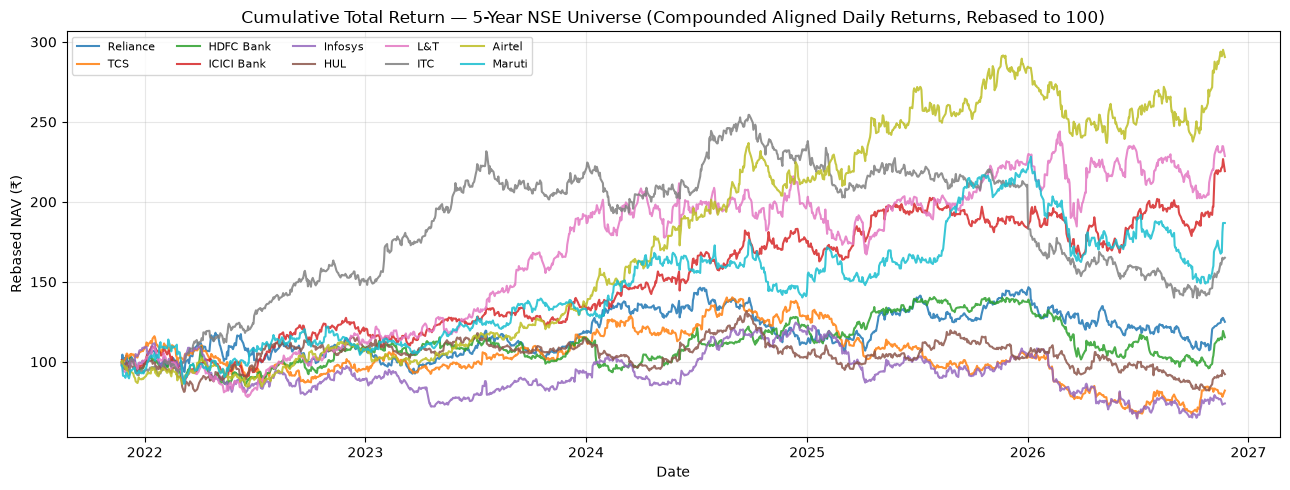

Plotted 10 assets over 1236 aligned daily return observations (2021-11-24 → 2026-11-23).


In [8]:
# ---------------------------------------------------------------------------
# Cumulative Total Return (Compounded Aligned Daily Simple Returns)
#
# FINANCIAL METHODOLOGY NOTE:
# Instead of naively dropping rows from raw prices before computing returns
# (which risks stitching disconnected dates into synthetic multi-session jumps),
# we calculate simple returns from the un-dropped prices DataFrame via the backend,
# then compound the resulting listwise-aligned daily returns:
#     NAV_t = 100 × prod_{s=1}^t (1 + R_{i,s})
# ---------------------------------------------------------------------------
aligned_returns_preview = calculate_simple_returns(prices=prices, aligned=True)
cumulative_returns = (1.0 + aligned_returns_preview).cumprod() * 100.0  # rebased to 100

fig, ax = plt.subplots(figsize=(13, 5))
for ticker in TICKERS:
    ax.plot(cumulative_returns.index, cumulative_returns[ticker],
            linewidth=1.5, label=TICKER_LABELS[ticker], alpha=0.85)

ax.set_title('Cumulative Total Return — 5-Year NSE Universe (Compounded Aligned Daily Returns, Rebased to 100)', fontsize=12)
ax.set_xlabel('Date')
ax.set_ylabel('Rebased NAV (₹)')
ax.legend(ncol=5, loc='upper left', fontsize=8)
ax.grid(True, alpha=0.3)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:.0f}'))
plt.tight_layout()
plt.show()
print(f"Plotted {len(TICKERS)} assets over {len(cumulative_returns)} aligned daily return observations ({cumulative_returns.index[0].date()} → {cumulative_returns.index[-1].date()}).")


---
## 6. Compute Historical Simple Returns & Expected Returns

### Formula Reference

**Daily Simple Return** (`FINANCIAL_METHODOLOGY.md §3.1.1`):
$$R_{i,t} = \frac{P_{adj,i,t}}{P_{adj,i,t-1}} - 1$$

**Annualised Arithmetic Expected Return** (`FINANCIAL_METHODOLOGY.md §2.2`):
$$\mu_i = 252 \times \bar{R}_i = 252 \times \frac{1}{T} \sum_{t=1}^T R_{i,t}$$

Simple returns are the **only** valid input for Markowitz optimisation because they are cross-sectionally additive ($R_{p,t} = \mathbf{w}^T \mathbf{R}_t$). Log returns are **not** used here.

Both calculations are delegated to the backend via `calculate_simple_returns()` and `calculate_expected_returns()`.

In [9]:
# ---------------------------------------------------------------------------
# Step 1: Calculate daily simple returns directly from raw un-dropped prices
#   - Raw prices DataFrame is passed directly to the backend
#   - Missing-session gaps produce NaN and are NEVER misclassified as 1-day returns
#   - aligned=True applies listwise-complete filtering to the RESULTING return matrix
# ---------------------------------------------------------------------------
returns: pd.DataFrame = calculate_simple_returns(
    prices=prices,  # Original un-dropped prices (preserves missing dates)
    aligned=True,   # Listwise-complete alignment applied to resulting return matrix
)

print(f"Daily simple returns shape: {returns.shape}  (T={returns.shape[0]} days × N={returns.shape[1]} assets)")
print(f"Date range               : {returns.index[0].date()} → {returns.index[-1].date()}")
print(f"Any NaN in returns       : {returns.isna().any().any()}")
print()

# ---------------------------------------------------------------------------
# Step 2: Calculate annualised arithmetic expected returns
#   - mu_i = 252 × mean(R_{i,daily})
#   - Canonical Markowitz input, NOT CAGR
# ---------------------------------------------------------------------------
expected_returns: pd.Series = calculate_expected_returns(
    data=returns,
    is_returns=True,
    trading_days_per_year=TRADING_DAYS_PER_YEAR,
    aligned=True,
)

print("Annualised Arithmetic Expected Returns (μᵢ):")
mu_df = pd.DataFrame({
    'Annualised μ (%)': (expected_returns * 100).round(2)
}).rename(index=TICKER_LABELS)
print(mu_df.to_string())


Daily simple returns shape: (1236, 10)  (T=1236 days × N=10 assets)
Date range               : 2021-11-24 → 2026-11-23
Any NaN in returns       : False

Annualised Arithmetic Expected Returns (μᵢ):
            Annualised μ (%)
Ticker                      
Airtel                 24.05
HDFC Bank               5.18
HUL                     0.52
ICICI Bank             17.98
Infosys                -2.67
ITC                    12.17
L&T                    19.86
Maruti                 15.48
Reliance                7.14
TCS                    -1.40


In [10]:
# ---------------------------------------------------------------------------
# Regression Test: Missing Intermediate Price Does Not Create Multi-Session Return
#
# Mathematically demonstrates that calculate_simple_returns():
#   1. Produces NaN when Day t-1 is missing (blocks synthetic 2-day return).
#   2. Produces NaN when Day t is missing.
#   3. Resumes genuine 1-day returns only when consecutive prices are present.
#   4. Under aligned=True, discards non-consecutive dates cleanly.
# ---------------------------------------------------------------------------
synth_dates = pd.date_range('2024-01-01', periods=4, freq='B')
# Day 0: 100.0, Day 1: NaN (missing), Day 2: 121.0, Day 3: 133.1
synth_prices = pd.DataFrame({
    'STOCK_A': [100.0, np.nan, 121.0, 133.1],
    'STOCK_B': [50.0, 52.0, 54.0, 56.0],
}, index=synth_dates)

# Unaligned return calculation
synth_returns_unaligned = calculate_simple_returns(synth_prices, aligned=False)

# Day 1: NaN because P_1 is missing
assert np.isnan(synth_returns_unaligned.loc[synth_dates[1], 'STOCK_A']), "Day 1 return must be NaN"
# Day 2: NaN because P_1 was missing; multi-session return (121/100 - 1 = +21%) is strictly blocked
assert np.isnan(synth_returns_unaligned.loc[synth_dates[2], 'STOCK_A']), "Day 2 return must be NaN (no multi-session 2-day jump)"
# Day 3: genuine 1-day return (133.1 / 121.0 - 1 = +10.0%)
assert np.isclose(synth_returns_unaligned.loc[synth_dates[3], 'STOCK_A'], 0.10), "Day 3 return must be 10%"

# Demonstrating the bug in naive dropna():
naive_prices = synth_prices.dropna(how='any')
naive_ret = (naive_prices['STOCK_A'] / naive_prices['STOCK_A'].shift(1) - 1.0).dropna()
assert np.isclose(naive_ret.loc[synth_dates[2]], 0.21), "Naive dropna would have falsely created a +21% 2-day return"

# Listwise-aligned return calculation retains only simultaneously valid 1-day returns
synth_returns_aligned = calculate_simple_returns(synth_prices, aligned=True)
assert len(synth_returns_aligned) == 1, "Only Day 3 has valid 1-day returns for all assets"
assert synth_returns_aligned.index[0] == synth_dates[3]

print("✓ Missing-observation return safety verified:")
print(f"  Day 1 return: {synth_returns_unaligned.loc[synth_dates[1], 'STOCK_A']} (missing price)")
print(f"  Day 2 return: {synth_returns_unaligned.loc[synth_dates[2], 'STOCK_A']} (multi-session jump blocked)")
print(f"  Day 3 return: {synth_returns_unaligned.loc[synth_dates[3], 'STOCK_A']:.1%} (consecutive 1-day return)")
print(f"  Aligned rows: {len(synth_returns_aligned)} (only genuine concurrent 1-day return)")


✓ Missing-observation return safety verified:
  Day 1 return: nan (missing price)
  Day 2 return: nan (multi-session jump blocked)
  Day 3 return: 10.0% (consecutive 1-day return)
  Aligned rows: 1 (only genuine concurrent 1-day return)


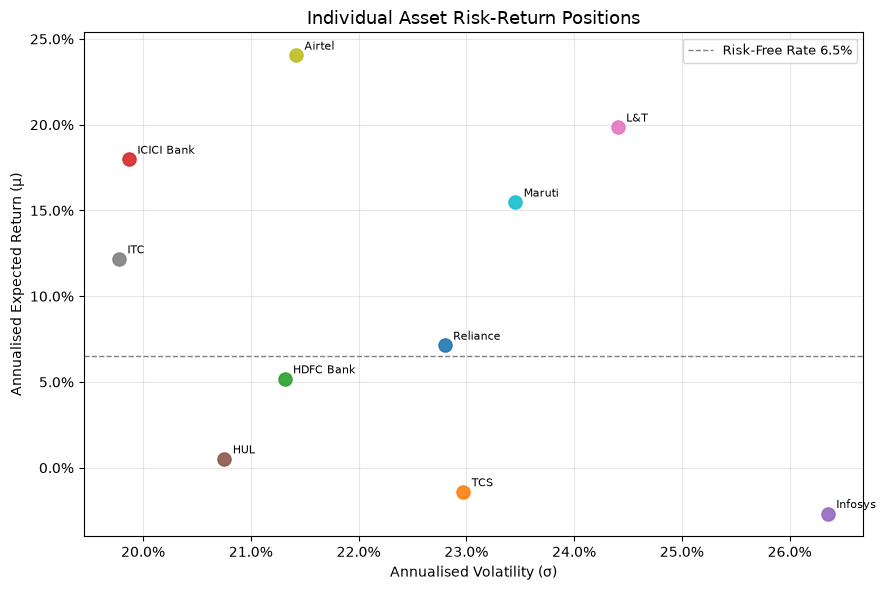

In [11]:
# Visualise individual asset risk-return characteristics
ann_vols = returns.std(ddof=1) * np.sqrt(TRADING_DAYS_PER_YEAR)

fig, ax = plt.subplots(figsize=(9, 6))
for ticker in TICKERS:
    label = TICKER_LABELS[ticker]
    ax.scatter(ann_vols[ticker], expected_returns[ticker],
               s=90, zorder=5, alpha=0.9)
    ax.annotate(label,
                xy=(ann_vols[ticker], expected_returns[ticker]),
                xytext=(6, 4), textcoords='offset points', fontsize=8)

ax.axhline(RISK_FREE_RATE, color='grey', linestyle='--', linewidth=1, label=f'Risk-Free Rate {RISK_FREE_RATE:.1%}')
ax.set_title('Individual Asset Risk-Return Positions', fontsize=13)
ax.set_xlabel('Annualised Volatility (σ)')
ax.set_ylabel('Annualised Expected Return (μ)')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 7. Covariance Estimation & Regularisation

### Why Not Just Use Sample Covariance?

The raw sample covariance matrix $\mathbf{S}$ is unbiased but numerically unstable when the number of assets $N$ is large relative to the observation window $T$. For the Markowitz optimiser, an ill-conditioned or near-singular covariance matrix produces extreme, unstable weights.

### Pipeline

| Step | Method | Purpose |
|---|---|---|
| 1 | Sample covariance ($\mathbf{S}$) | Baseline unbiased estimator |
| 2 | Ledoit-Wolf shrinkage ($\mathbf{\Sigma}_{LW}$) | Reduce estimation error by shrinking towards scaled identity |
| 3 | Higham PD projection | Guarantee strict positive-definiteness numerically |

**Ledoit-Wolf Formula** (`FINANCIAL_METHODOLOGY.md §4.1`):
$$\mathbf{\Sigma}_{LW} = (1-\hat{\delta})\,\mathbf{S} + \hat{\delta}\,\mu_{var}\,\mathbf{I}$$
where $\hat{\delta} \in [0,1]$ is the analytically optimal shrinkage intensity and $\mu_{var} = \text{tr}(\mathbf{S})/N$ is the mean variance.

**Annualisation** (`FINANCIAL_METHODOLOGY.md §2.2`):
$$\mathbf{\Sigma}_{ann} = 252 \times \mathbf{\Sigma}_{daily}$$

In [12]:
# ---------------------------------------------------------------------------
# Step 1: Sample covariance (annualised)
# ---------------------------------------------------------------------------
cov_sample: pd.DataFrame = calculate_sample_covariance(
    returns=returns,
    trading_days_per_year=TRADING_DAYS_PER_YEAR,
)
print(f"Sample covariance shape : {cov_sample.shape}")

# ---------------------------------------------------------------------------
# Step 2: Ledoit-Wolf shrinkage (annualised)
# ---------------------------------------------------------------------------
cov_lw: pd.DataFrame = calculate_ledoit_wolf_covariance(
    returns=returns,
    trading_days_per_year=TRADING_DAYS_PER_YEAR,
)

lw_model = fit_ledoit_wolf(returns=returns)
shrinkage_intensity = float(lw_model.shrinkage_)

print(f"Ledoit-Wolf shrinkage intensity (δ̂)  : {shrinkage_intensity:.4f}")
print(f"  δ̂ ≈ 0 → sample matrix is reliable")
print(f"  δ̂ ≈ 1 → heavy shrinkage towards diagonal (high estimation error)")

# ---------------------------------------------------------------------------
# Step 3: Higham PD projection to ensure strict positive-definiteness
# ---------------------------------------------------------------------------
cov_regularised: pd.DataFrame = regularize_covariance_higham(covariance=cov_lw)

eigenvalues = np.linalg.eigvalsh(cov_regularised.values)
print(f"\nFinal covariance eigenvalues (min, max): ({eigenvalues.min():.6f}, {eigenvalues.max():.6f})")
print(f"Condition number κ(Σ)                  : {eigenvalues.max() / eigenvalues.min():.1f}")
print(f"All eigenvalues > 0                    : {bool(eigenvalues.min() > 0)}")

# This is the covariance used in all subsequent optimisations
COV = cov_regularised
MU  = expected_returns
print(f"\nCovariance matrix ({COV.shape[0]}×{COV.shape[1]}) is ready for optimisation.")

Sample covariance shape : (10, 10)
Ledoit-Wolf shrinkage intensity (δ̂)  : 0.0196
  δ̂ ≈ 0 → sample matrix is reliable
  δ̂ ≈ 1 → heavy shrinkage towards diagonal (high estimation error)

Final covariance eigenvalues (min, max): (0.015963, 0.182498)
Condition number κ(Σ)                  : 11.4
All eigenvalues > 0                    : True

Covariance matrix (10×10) is ready for optimisation.


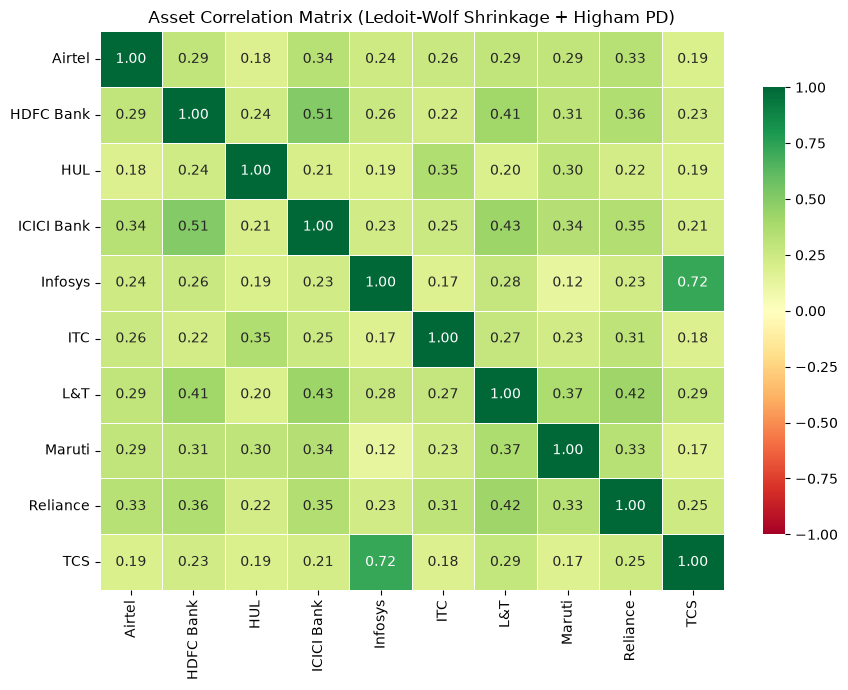

In [13]:
# Visualise annualised correlation matrix (derived from the regularised covariance)
std_diag = np.sqrt(np.diag(COV.values))
corr_matrix = COV.values / np.outer(std_diag, std_diag)
corr_df = pd.DataFrame(
    corr_matrix,
    index=[TICKER_LABELS[t] for t in COV.index],
    columns=[TICKER_LABELS[t] for t in COV.columns],
)

try:
    import seaborn as sns
    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(corr_df, annot=True, fmt='.2f', cmap='RdYlGn',
                vmin=-1, vmax=1, center=0, linewidths=0.5,
                ax=ax, cbar_kws={'shrink': 0.8})
    ax.set_title('Asset Correlation Matrix (Ledoit-Wolf Shrinkage + Higham PD)', fontsize=12)
    plt.tight_layout()
    plt.show()
except ImportError:
    print("seaborn not installed — displaying correlation matrix as a table:")
    print(corr_df.round(2).to_string())

---
## 8. Global Minimum Variance Portfolio

### Financial Definition

The **Global Minimum Variance (GMV) portfolio** is the portfolio on the efficient frontier with the **lowest achievable annualised volatility** given the investment universe and long-only constraints.

### Optimisation Problem

$$\min_{\mathbf{w}} \; \frac{1}{2}\,\mathbf{w}^T \mathbf{\Sigma} \,\mathbf{w}$$

Subject to:
$$\sum_{i=1}^N w_i = 1 \qquad (\text{fully invested})$$
$$0 \leq w_i \leq 1 \qquad (\text{long-only})$$

Notably, the GMV **does not use expected returns** — it is a pure risk-minimisation problem. This makes it less sensitive to estimation errors in $\boldsymbol{\mu}$.

Solved via SLSQP with analytical gradient $\nabla_w f = \mathbf{\Sigma}\mathbf{w}$.

In [14]:
try:
    gmv_result = optimize_global_minimum_variance(
        covariance=COV,
    )
except (FinancialCalculationError, NonPositiveDefiniteMatrixError, IllConditionedMatrixError) as exc:
    print(f"GMV optimisation failed: {exc}")
    raise

gmv_ret = float(MU @ gmv_result.weights)
gmv_vol = float(gmv_result.volatility)
gmv_sharpe = (gmv_ret - RISK_FREE_RATE) / gmv_vol

print("=" * 50)
print("Global Minimum Variance Portfolio")
print("=" * 50)
print(f"  Annualised Volatility   : {gmv_vol:.2%}")
print(f"  Annualised Exp. Return  : {gmv_ret:.2%}")
print(f"  Sharpe Ratio            : {gmv_sharpe:.4f}")
print(f"  Solver converged        : {gmv_result.success}")
print(f"  Solver iterations       : {gmv_result.iterations}")
print()

print("GMV Portfolio Weights:")
gmv_weights_df = pd.DataFrame({
    'Weight (%)': (gmv_result.weights * 100).round(2)
}).rename(index=TICKER_LABELS)
print(gmv_weights_df.to_string())
print(f"  Total: {gmv_weights_df['Weight (%)'].sum():.2f}%")

Global Minimum Variance Portfolio
  Annualised Volatility   : 12.76%
  Annualised Exp. Return  : 9.88%
  Sharpe Ratio            : 0.2649
  Solver converged        : True
  Solver iterations       : 22

GMV Portfolio Weights:
            Weight (%)
Ticker                
Airtel           13.74
HDFC Bank         9.41
HUL              16.81
ICICI Bank       13.98
Infosys           0.00
ITC              18.54
L&T               0.03
Maruti            6.99
Reliance          5.05
TCS              15.45
  Total: 100.00%


---
## 9. Maximum Sharpe Ratio / Tangency Portfolio

### Financial Definition

The **Tangency Portfolio** is the portfolio of risky assets that maximises the **Sharpe Ratio** — the risk-adjusted excess return over the risk-free asset. It is the point on the efficient frontier where the Capital Allocation Line is tangent.

### Optimisation Problem

$$\max_{\mathbf{w}} \; S(\mathbf{w}) = \frac{\mathbf{w}^T \boldsymbol{\mu} - r_f}{\sqrt{\mathbf{w}^T \mathbf{\Sigma} \mathbf{w}}}$$

Subject to:
$$\sum_{i=1}^N w_i = 1, \quad 0 \leq w_i \leq 1$$

**Risk-free rate:** $r_f = 6.5\%$ p.a. (91-day G-Sec T-Bill).

Unlike the GMV, this portfolio uses both $\boldsymbol{\mu}$ and $\boldsymbol{\Sigma}$ and is therefore more sensitive to expected-return estimation errors.

In [15]:
try:
    tangency_result = optimize_maximum_sharpe_ratio(
        expected_returns=MU,
        covariance=COV,
        risk_free_rate=RISK_FREE_RATE,
    )
except (FinancialCalculationError, NonPositiveDefiniteMatrixError, IllConditionedMatrixError) as exc:
    print(f"Tangency optimisation failed: {exc}")
    raise

print("=" * 50)
print("Maximum Sharpe Ratio / Tangency Portfolio")
print("=" * 50)
print(f"  Annualised Volatility   : {tangency_result.volatility:.2%}")
print(f"  Annualised Exp. Return  : {tangency_result.expected_return:.2%}")
print(f"  Sharpe Ratio            : {tangency_result.sharpe_ratio:.4f}")
print(f"  Risk-Free Rate          : {tangency_result.risk_free_rate:.2%}")
print(f"  Solver converged        : {tangency_result.success}")
print()

print("Tangency Portfolio Weights:")
tan_weights_df = pd.DataFrame({
    'Weight (%)': (tangency_result.weights * 100).round(2)
}).rename(index=TICKER_LABELS)
print(tan_weights_df.to_string())
print(f"  Total: {tan_weights_df['Weight (%)'].sum():.2f}%")

Maximum Sharpe Ratio / Tangency Portfolio
  Annualised Volatility   : 16.83%
  Annualised Exp. Return  : 21.76%
  Sharpe Ratio            : 0.9067
  Risk-Free Rate          : 6.50%
  Solver converged        : True

Tangency Portfolio Weights:
            Weight (%)
Ticker                
Airtel           57.20
HDFC Bank         0.00
HUL               0.00
ICICI Bank       22.75
Infosys           0.00
ITC               0.00
L&T              18.56
Maruti            1.49
Reliance          0.00
TCS               0.00
  Total: 100.00%


---
## 10. Efficient Frontier

### Financial Definition

The **Efficient Frontier** is the set of portfolios that deliver the **maximum expected return for each given level of risk** (volatility). No diversification gain is possible above this boundary.

### Parametric Computation

For each target return $\mu_p \in [\mu_{min}, \mu_{max}]$, solve:

$$\min_{\mathbf{w}} \; \frac{1}{2}\mathbf{w}^T \mathbf{\Sigma} \mathbf{w} \quad \text{s.t.} \quad \mathbf{w}^T \boldsymbol{\mu} = \mu_p, \; \sum w_i = 1, \; w_i \geq 0$$

**Efficient branch:** $\mu_p \geq \mu_{GMV}$ — these are genuinely efficient portfolios.  
**Inefficient (lower) branch:** $\mu_p < \mu_{GMV}$ — a higher-return portfolio with identical or lower risk always exists.

The backend computes 50 frontier points by default (configurable).

In [16]:
try:
    frontier_result = compute_efficient_frontier(
        expected_returns=MU,
        covariance=COV,
        n_points=100,  # 100 uniformly-spaced return targets
    )
except (FinancialCalculationError, NonPositiveDefiniteMatrixError, IllConditionedMatrixError) as exc:
    print(f"Efficient frontier computation failed: {exc}")
    raise

print("=" * 50)
print("Efficient Frontier Summary")
print("=" * 50)
print(f"  Total frontier points     : {len(frontier_result.portfolios)}")
print(f"  Efficient portfolios      : {sum(1 for p in frontier_result.portfolios if p.is_efficient)}")
print(f"  Inefficient portfolios    : {sum(1 for p in frontier_result.portfolios if not p.is_efficient)}")
print(f"  GMV volatility (frontier) : {frontier_result.gmv_portfolio.volatility:.2%}")
print(f"  GMV return (frontier)     : {float(MU @ frontier_result.gmv_portfolio.weights):.2%}")

Efficient Frontier Summary
  Total frontier points     : 100
  Efficient portfolios      : 53
  Inefficient portfolios    : 47
  GMV volatility (frontier) : 12.76%
  GMV return (frontier)     : 9.88%


---
## 11. Capital Allocation Line (CAL)

### Financial Definition

The **Capital Allocation Line** represents all portfolios formed by combining the **risk-free asset** (T-Bill) with the **tangency portfolio** in varying proportions.

$$E[R_c] = r_f + \underbrace{\frac{\mu_T - r_f}{\sigma_T}}_{\text{Sharpe slope}} \times \sigma_c$$

where:
- $r_f$ = risk-free rate (6.5%)
- $\mu_T, \sigma_T$ = tangency portfolio expected return and volatility
- $\sigma_c$ = complete-portfolio volatility (the choice variable)

**Weight decomposition** at any point on the CAL:
$$w_T = \frac{\sigma_c}{\sigma_T} \quad (\text{tangency fraction}), \quad w_{r_f} = 1 - w_T \quad (\text{risk-free fraction})$$

Under the **MVP long-only, fully-invested constraint**, no leverage is permitted: $0 \leq w_T \leq 1$, so $\sigma_c \in [0, \sigma_T]$.

In [17]:
try:
    cal_result = generate_cal_coordinates(
        tangency_portfolio=tangency_result,
        n_points=200,
        allow_leverage=False,  # Long-only MVP constraint
    )
except (FinancialCalculationError, InsufficientDataError) as exc:
    print(f"CAL generation failed: {exc}")
    raise

print("=" * 50)
print("Capital Allocation Line")
print("=" * 50)
print(f"  CAL Slope (Sharpe Ratio of Tangency): {cal_result.slope:.4f}")
print(f"  Risk-Free Rate                       : {cal_result.risk_free_rate:.2%}")
print(f"  Number of CAL coordinates            : {len(cal_result.coordinates)}")
print(f"  CAL volatility range                 : 0.00% → {max(c.volatility for c in cal_result.coordinates):.2%}")

Capital Allocation Line
  CAL Slope (Sharpe Ratio of Tangency): 0.9067
  Risk-Free Rate                       : 6.50%
  Number of CAL coordinates            : 200
  CAL volatility range                 : 0.00% → 16.83%


---
## 12. Monte Carlo Portfolio Cloud

To visually demonstrate the efficiency gain of optimisation over naive random allocation, we generate 5,000 random long-only portfolios using the backend Monte Carlo simulator. These form a **cloud** in risk-return space — all feasible portfolios lie below and to the right of the efficient frontier.

In [18]:
try:
    mc_result = simulate_monte_carlo_portfolios(
        expected_returns=MU,
        covariance=COV,
        num_portfolios=5000,
        risk_free_rate=RISK_FREE_RATE,
        random_seed=RANDOM_SEED,
    )
    mc_vols    = mc_result.volatilities
    mc_returns = mc_result.expected_returns
    mc_sharpes = mc_result.sharpe_ratios
    print(f"Monte Carlo: {len(mc_vols):,} simulated portfolios generated.")
    print(f"  Simulated GMV vol : {mc_result.simulated_gmv.volatility:.2%}")
    print(f"  Simulated max SR  : {max(mc_sharpes):.4f}")
    MONTE_CARLO_AVAILABLE = True
except Exception as exc:
    print(f"Monte Carlo simulation unavailable: {exc}")
    MONTE_CARLO_AVAILABLE = False

Monte Carlo: 5,000 simulated portfolios generated.
  Simulated GMV vol : 12.88%
  Simulated max SR  : 0.7702


---
## 13. Full Risk-Return Visualisation

The chart below synthesises the complete mean-variance analysis on a single risk-return diagram:

- **Grey scatter cloud** — 5,000 Monte Carlo random portfolios (the feasible set).
- **Blue curve** — Efficient Frontier (upper efficient branch).
- **Dashed red curve** — Inefficient (lower) frontier branch.
- **Green star** — Global Minimum Variance (GMV) portfolio.
- **Orange star** — Maximum Sharpe Ratio / Tangency portfolio.
- **Orange dashed line** — Capital Allocation Line.
- **Grey diamond** — Risk-free asset at $\sigma=0$, $\mu = r_f$.
- **Coloured dots** — Individual asset risk-return positions.

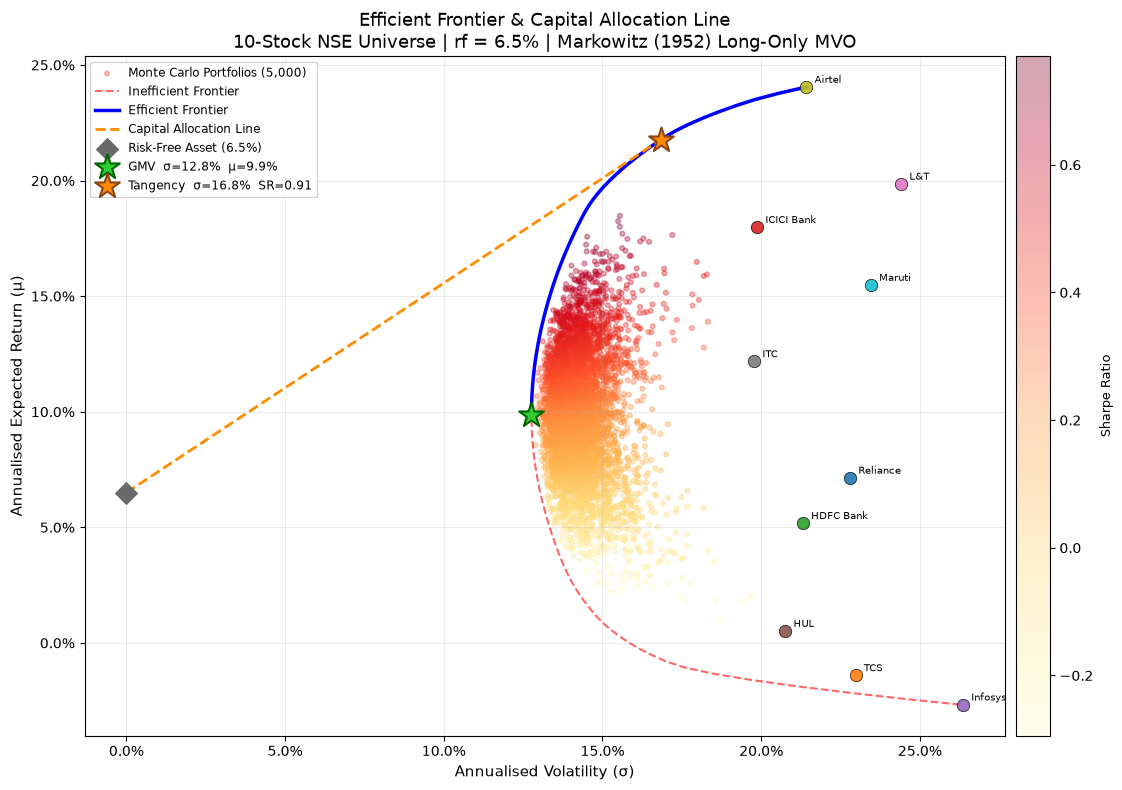

In [19]:
# ---------------------------------------------------------------------------
# Extract frontier coordinates
# ---------------------------------------------------------------------------
efficient_vols  = [p.volatility for p in frontier_result.portfolios if p.is_efficient]
efficient_rets  = [p.expected_return for p in frontier_result.portfolios if p.is_efficient]
inefficient_vols = [p.volatility for p in frontier_result.portfolios if not p.is_efficient]
inefficient_rets = [p.expected_return for p in frontier_result.portfolios if not p.is_efficient]

# Individual asset annualised volatilities and expected returns
asset_vols = returns.std(ddof=1) * np.sqrt(TRADING_DAYS_PER_YEAR)

# CAL coordinates
cal_vols = [c.volatility for c in cal_result.coordinates]
cal_rets = [c.expected_return for c in cal_result.coordinates]

# ---------------------------------------------------------------------------
# Compose the chart
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 8))

# 1. Monte Carlo cloud (colour-coded by Sharpe ratio)
if MONTE_CARLO_AVAILABLE:
    scatter = ax.scatter(
        mc_vols, mc_returns,
        c=mc_sharpes, cmap='YlOrRd', alpha=0.35, s=12, zorder=1,
        label='Monte Carlo Portfolios (5,000)',
    )
    cbar = plt.colorbar(scatter, ax=ax, pad=0.01)
    cbar.set_label('Sharpe Ratio', fontsize=9)

# 2. Inefficient (lower) frontier branch
if inefficient_vols:
    ax.plot(inefficient_vols, inefficient_rets,
            'r--', linewidth=1.5, alpha=0.6, label='Inefficient Frontier', zorder=2)

# 3. Efficient frontier
ax.plot(efficient_vols, efficient_rets,
        'b-', linewidth=2.5, label='Efficient Frontier', zorder=3)

# 4. Capital Allocation Line
ax.plot(cal_vols, cal_rets,
        '--', color='darkorange', linewidth=2, label='Capital Allocation Line', zorder=4)

# 5. Risk-free asset
ax.scatter([0], [RISK_FREE_RATE],
           marker='D', s=120, color='dimgray', zorder=6, label=f'Risk-Free Asset ({RISK_FREE_RATE:.1%})')

# 6. GMV portfolio
ax.scatter([gmv_vol], [gmv_ret],
           marker='*', s=350, color='limegreen', edgecolors='darkgreen',
           linewidths=1.5, zorder=7, label=f'GMV  σ={gmv_vol:.1%}  μ={gmv_ret:.1%}')

# 7. Tangency portfolio
ax.scatter([tangency_result.volatility], [tangency_result.expected_return],
           marker='*', s=350, color='darkorange', edgecolors='saddlebrown',
           linewidths=1.5, zorder=7,
           label=f'Tangency  σ={tangency_result.volatility:.1%}  SR={tangency_result.sharpe_ratio:.2f}')

# 8. Individual assets
ASSET_COLORS = plt.cm.tab10(np.linspace(0, 1, len(TICKERS)))
for i, ticker in enumerate(TICKERS):
    ax.scatter(
        asset_vols[ticker], expected_returns[ticker],
        s=80, color=ASSET_COLORS[i], edgecolors='black', linewidths=0.5,
        zorder=8, alpha=0.9,
    )
    ax.annotate(
        TICKER_LABELS[ticker],
        xy=(asset_vols[ticker], expected_returns[ticker]),
        xytext=(6, 3), textcoords='offset points', fontsize=7.5, color='black',
    )

# Formatting
ax.set_title(
    'Efficient Frontier & Capital Allocation Line\n'
    f'10-Stock NSE Universe | rf = {RISK_FREE_RATE:.1%} | Markowitz (1952) Long-Only MVO',
    fontsize=13,
)
ax.set_xlabel('Annualised Volatility (σ)', fontsize=11)
ax.set_ylabel('Annualised Expected Return (μ)', fontsize=11)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(fontsize=8.5, loc='upper left', framealpha=0.9)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

---
## 14. Portfolio Weights Summary Table

Portfolio Weights Comparison
            Equal Weight (%)  GMV (%)  Tangency (%)
Reliance                10.0    13.74         57.20
TCS                     10.0     9.41          0.00
HDFC Bank               10.0    16.81          0.00
ICICI Bank              10.0    13.98         22.75
Infosys                 10.0     0.00          0.00
HUL                     10.0    18.54          0.00
L&T                     10.0     0.03         18.56
ITC                     10.0     6.99          1.49
Airtel                  10.0     5.05          0.00
Maruti                  10.0    15.45          0.00
Total (%)              100.0   100.00        100.00


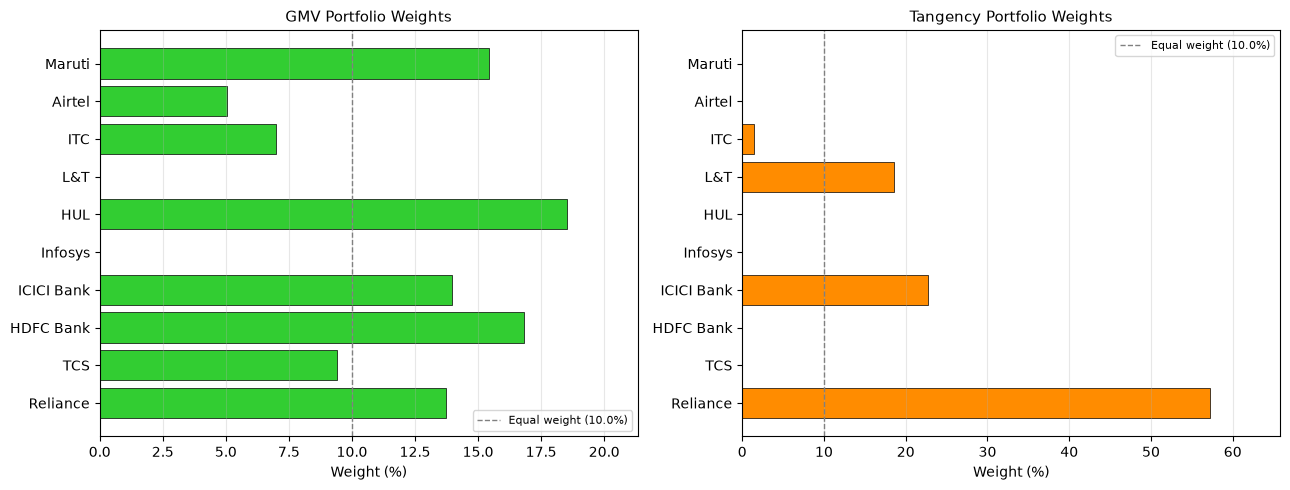

In [20]:
# ---------------------------------------------------------------------------
# Side-by-side portfolio weights display
# ---------------------------------------------------------------------------
weights_summary = pd.DataFrame({
    'Equal Weight (%)' : [100.0 / len(TICKERS)] * len(TICKERS),
    'GMV (%)' : (gmv_result.weights.values * 100).round(2),
    'Tangency (%)' : (tangency_result.weights.values * 100).round(2),
}, index=[TICKER_LABELS[t] for t in TICKERS])

totals = weights_summary.sum()
totals.name = 'Total (%)'
weights_summary = pd.concat([weights_summary, totals.to_frame().T])

print("Portfolio Weights Comparison")
print("=" * 60)
print(weights_summary.to_string())

# Bar chart
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_data = weights_summary.iloc[:-1]  # exclude Total row

for ax_idx, (col, color) in enumerate([
    ('GMV (%)', 'limegreen'),
    ('Tangency (%)', 'darkorange'),
]):
    ax = axes[ax_idx]
    bars = ax.barh(plot_data.index, plot_data[col], color=color, edgecolor='black', linewidth=0.5)
    ax.set_xlabel('Weight (%)')
    ax.set_title(col.replace(' (%)', ' Portfolio Weights'), fontsize=11)
    ax.axvline(100.0 / len(TICKERS), color='grey', linestyle='--', linewidth=1,
               label=f'Equal weight ({100.0/len(TICKERS):.1f}%)')
    ax.legend(fontsize=8)
    ax.grid(True, axis='x', alpha=0.3)
    ax.set_xlim(0, max(plot_data[col].max() * 1.15, 15))

plt.tight_layout()
plt.show()

---
## 15. Financial Interpretation

### Global Minimum Variance Portfolio

The GMV portfolio is the starting point of the efficient frontier. It minimises annualised volatility over the entire investment universe without reference to expected returns. Its practical utility:
- Useful for **risk-averse investors** who prioritise capital preservation over return maximisation.
- **Less sensitive** to expected-return estimation errors than the Tangency portfolio.
- Typically concentrated in **lower-volatility, negatively-correlated assets**.

### Tangency Portfolio

The Tangency portfolio maximises the Sharpe Ratio — the excess return per unit of risk taken. Under CAPM assumptions, all rational mean-variance investors hold a mix of this portfolio and the risk-free asset, regardless of their risk preference. In practice:
- Sensitive to **estimation errors in expected returns** (mean returns are notoriously hard to estimate from historical data).
- May concentrate in assets with high recent returns, introducing **look-back bias** concerns.
- For robust production use, consider **shrinking expected returns** or combining with a risk-based model.

### Capital Allocation Line

The CAL enables **personalised risk-targeting**: an investor selects their desired complete-portfolio volatility $\sigma_c$, then invests $w_T = \sigma_c / \sigma_T$ in the tangency portfolio and the remainder in T-Bills. No point on the CAL is dominated — it offers the best Sharpe Ratio for every risk level.

### Diversification Benefit

The Monte Carlo cloud shows that **the vast majority of random portfolios lie well below and to the right of the efficient frontier** — investors who pick stocks randomly or use equal-weight allocations leave significant Sharpe Ratio on the table.

---
## 16. Backend Validation Checks

The following assertions verify that the notebook results are **internally consistent** with backend guarantees. These are mathematical identity checks, not financial forecasts.

In [21]:
PASS_SYMBOL = "✓"
FAIL_SYMBOL = "✗"
results = []

def check(name: str, condition: bool, detail: str = "") -> None:
    symbol = PASS_SYMBOL if condition else FAIL_SYMBOL
    results.append((name, condition, detail))
    print(f"  {symbol}  {name}" + (f"  —  {detail}" if detail else ""))

print("Backend Validation Checks")
print("=" * 60)

# Returns checks
check("Simple returns: no NaN", not returns.isna().any().any())
check("Simple returns: finite values", np.isfinite(returns.values).all())

# Expected returns checks
check("Expected returns: N assets", len(expected_returns) == len(TICKERS),
      f"got {len(expected_returns)}, expected {len(TICKERS)}")
check("Expected returns: finite", np.isfinite(expected_returns.values).all())

# Covariance checks
eigs = np.linalg.eigvalsh(COV.values)
check("Covariance: positive definite", bool(eigs.min() > 0),
      f"min eigenvalue = {eigs.min():.2e}")
check("Covariance: symmetric",
      bool(np.max(np.abs(COV.values - COV.values.T)) < 1e-10))

# GMV checks
check("GMV: solver converged", gmv_result.success)
check("GMV: weights sum to 1",
      abs(gmv_result.weights.sum() - 1.0) < 1e-5,
      f"sum = {gmv_result.weights.sum():.8f}")
check("GMV: long-only",
      bool((gmv_result.weights.values >= -1e-7).all()),
      f"min weight = {gmv_result.weights.min():.4f}")

# ISSUE 2: GMV volatility <= min constituent asset volatility
sample_asset_vols = returns.std(ddof=1) * np.sqrt(TRADING_DAYS_PER_YEAR)
cov_asset_vols = pd.Series(np.sqrt(np.diag(COV.values)), index=COV.columns)
min_sample_vol = float(sample_asset_vols.min())
min_cov_vol = float(cov_asset_vols.min())
min_individual_vol = min(min_sample_vol, min_cov_vol)
check("GMV: volatility <= all individual assets",
      bool(gmv_vol <= min_individual_vol + 1e-6),
      f"GMV={gmv_vol:.2%}, min asset={min_individual_vol:.2%} ({sample_asset_vols.idxmin()})")

# Tangency checks
check("Tangency: solver converged", tangency_result.success)
check("Tangency: weights sum to 1",
      abs(tangency_result.weights.sum() - 1.0) < 1e-5,
      f"sum = {tangency_result.weights.sum():.8f}")
check("Tangency: long-only",
      bool((tangency_result.weights.values >= -1e-7).all()))
check("Tangency: Sharpe > GMV Sharpe",
      tangency_result.sharpe_ratio >= gmv_sharpe,
      f"SR_T={tangency_result.sharpe_ratio:.4f} vs SR_GMV={gmv_sharpe:.4f}")

# CAL checks
cal_slope_check = abs(cal_result.slope - tangency_result.sharpe_ratio) < 1e-6
check("CAL: slope == Tangency Sharpe Ratio", cal_slope_check,
      f"slope={cal_result.slope:.6f}, SR={tangency_result.sharpe_ratio:.6f}")
check("CAL: starts at risk-free rate",
      abs(cal_result.coordinates[0].expected_return - RISK_FREE_RATE) < 1e-10)
check("CAL: ends at tangency portfolio",
      abs(cal_result.coordinates[-1].volatility - tangency_result.volatility) < 1e-6)

# Efficient frontier checks
frontier_gmv_vol = frontier_result.gmv_portfolio.volatility
check("Frontier: GMV volatility consistent with standalone GMV",
      abs(frontier_gmv_vol - gmv_vol) < 1e-4,
      f"frontier={frontier_gmv_vol:.4%}, standalone={gmv_vol:.4%}")

# Return safety regression check
check("Return safety: missing price does not create synthetic return",
      bool(np.isnan(synth_returns_unaligned.loc[synth_dates[2], 'STOCK_A'])),
      "Day 2 return is strictly NaN after Day 1 missing price")

# Trading calendar regression checks
check("Calendar: Saturday maps to previous trading day", cal_reg_sat == date(2026, 1, 23))
check("Calendar: Sunday maps to previous trading day", cal_reg_sun == date(2026, 1, 23))
check("Calendar: Weekday holiday maps to previous trading day", cal_reg_hol == date(2026, 1, 23))
check("Calendar: Weekday before 16:00 IST maps to previous trading day", cal_reg_pre == date(2026, 1, 23))
check("Calendar: Weekday after 16:00 IST maps to completed session", cal_reg_post == date(2026, 1, 27))
check("Data cutoff: latest observation aligns with completed session", prices.index[-1].date() == END_DATE,
      f"{prices.index[-1].date()} == {END_DATE}")

print()
passed = sum(1 for _, ok, _ in results if ok)
failed = sum(1 for _, ok, _ in results if not ok)
print(f"Results: {passed} passed, {failed} failed out of {len(results)} checks.")
if failed > 0:
    print("\nFailed checks:")
    for name, ok, detail in results:
        if not ok:
            print(f"  {FAIL_SYMBOL} {name}: {detail}")


Backend Validation Checks
  ✓  Simple returns: no NaN
  ✓  Simple returns: finite values
  ✓  Expected returns: N assets  —  got 10, expected 10
  ✓  Expected returns: finite
  ✓  Covariance: positive definite  —  min eigenvalue = 1.60e-02
  ✓  Covariance: symmetric
  ✓  GMV: solver converged
  ✓  GMV: weights sum to 1  —  sum = 1.00000000
  ✓  GMV: long-only  —  min weight = 0.0000
  ✓  GMV: volatility <= all individual assets  —  GMV=12.76%, min asset=19.78% (ITC.NS)
  ✓  Tangency: solver converged
  ✓  Tangency: weights sum to 1  —  sum = 1.00000000
  ✓  Tangency: long-only
  ✓  Tangency: Sharpe > GMV Sharpe  —  SR_T=0.9067 vs SR_GMV=0.2649
  ✓  CAL: slope == Tangency Sharpe Ratio  —  slope=0.906708, SR=0.906708
  ✓  CAL: starts at risk-free rate
  ✓  CAL: ends at tangency portfolio
  ✓  Frontier: GMV volatility consistent with standalone GMV  —  frontier=12.7629%, standalone=12.7629%
  ✓  Return safety: missing price does not create synthetic return  —  Day 2 return is strictly NaN

---
## 17. Key Observations & Conclusions

### Summary Table

In [22]:
# Summary of key portfolio metrics
eq_weights = np.full(len(TICKERS), 1.0 / len(TICKERS))
eq_ret = float(MU @ eq_weights)
eq_vol = float(np.sqrt(eq_weights.T @ COV.values @ eq_weights))
eq_sr  = (eq_ret - RISK_FREE_RATE) / eq_vol

summary_df = pd.DataFrame({
    'Ann. Return (%)' : [eq_ret * 100, gmv_ret * 100, tangency_result.expected_return * 100],
    'Ann. Vol (%)'    : [eq_vol * 100, gmv_vol * 100, tangency_result.volatility * 100],
    'Sharpe Ratio'    : [eq_sr, gmv_sharpe, tangency_result.sharpe_ratio],
}, index=['Equal Weight', 'GMV', 'Tangency (Max SR)'])

print("Portfolio Performance Summary")
print("=" * 55)
print(summary_df.round(2).to_string())
print()
print(f"Risk-Free Rate   : {RISK_FREE_RATE:.2%}")
print(f"Annualisation    : {TRADING_DAYS_PER_YEAR} trading days/year")
print(f"Covariance method: Ledoit-Wolf shrinkage + Higham PD projection")
print(f"Data window      : {returns.index[0].date()} → {returns.index[-1].date()} ({len(returns)} aligned daily return observations across {len(prices)} price sessions)")


Portfolio Performance Summary
                   Ann. Return (%)  Ann. Vol (%)  Sharpe Ratio
Equal Weight                  9.83         13.33          0.25
GMV                           9.88         12.76          0.26
Tangency (Max SR)            21.76         16.83          0.91

Risk-Free Rate   : 6.50%
Annualisation    : 252 trading days/year
Covariance method: Ledoit-Wolf shrinkage + Higham PD projection
Data window      : 2021-11-24 → 2026-11-23 (1236 aligned daily return observations across 1237 price sessions)


In [23]:
print("=" * 65)
print("Conclusions & Key Observations")
print("=" * 65)
print()
print("1. DIVERSIFICATION BENEFIT")
print(f"   The GMV portfolio achieves σ = {gmv_vol:.1%} vs the lowest individual")
print(f"   asset volatility of {min_sample_vol:.1%} ({sample_asset_vols.idxmin()}) and median of {sample_asset_vols.median():.1%} —")
print(f"   demonstrating the Markowitz diversification effect where portfolio risk")
print(f"   is strictly lower than every constituent asset.")
print()
print("2. SHARPE RATIO IMPROVEMENT")
print(f"   Tangency SR = {tangency_result.sharpe_ratio:.2f} vs Equal-Weight SR = {eq_sr:.2f} —")
print(f"   optimisation delivers a meaningful risk-adjusted improvement.")
print()
print("3. GMV vs TANGENCY TRADE-OFF")
print(f"   GMV: lower vol ({gmv_vol:.1%}) but lower return ({gmv_ret:.1%}).")
print(f"   Tangency: higher return ({tangency_result.expected_return:.1%}) but higher vol ({tangency_result.volatility:.1%}).")
print(f"   Investors with lower risk tolerance prefer GMV; higher, prefer Tangency.")
print()
print("4. CAL — PERSONALISED RISK TARGETING")
print(f"   The CAL (slope = {cal_result.slope:.2f}) allows any investor to match their")
print(f"   desired volatility by blending T-Bills and the Tangency portfolio.")
print()
print("5. KNOWN LIMITATIONS")
print("   - Expected returns estimated from 5-year historical data are noisy.")
print("   - Markowitz optimisation is sensitive to these estimates.")
print("   - Long-only constraints produce sparse, concentrated portfolios.")
print("   - Forward performance cannot be inferred from historical optimisation.")


Conclusions & Key Observations

1. DIVERSIFICATION BENEFIT
   The GMV portfolio achieves σ = 12.8% vs the lowest individual
   asset volatility of 19.8% (ITC.NS) and median of 22.1% —
   demonstrating the Markowitz diversification effect where portfolio risk
   is strictly lower than every constituent asset.

2. SHARPE RATIO IMPROVEMENT
   Tangency SR = 0.91 vs Equal-Weight SR = 0.25 —
   optimisation delivers a meaningful risk-adjusted improvement.

3. GMV vs TANGENCY TRADE-OFF
   GMV: lower vol (12.8%) but lower return (9.9%).
   Tangency: higher return (21.8%) but higher vol (16.8%).
   Investors with lower risk tolerance prefer GMV; higher, prefer Tangency.

4. CAL — PERSONALISED RISK TARGETING
   The CAL (slope = 0.91) allows any investor to match their
   desired volatility by blending T-Bills and the Tangency portfolio.

5. KNOWN LIMITATIONS
   - Expected returns estimated from 5-year historical data are noisy.
   - Markowitz optimisation is sensitive to these estimates.
   - Lo

---

## Appendix — Module Versions

In [24]:
import scipy
import sklearn
import matplotlib

print("Quantamental AI Backend Notebook — Dependency Versions")
print(f"  Python      : {sys.version.split()[0]}")
print(f"  NumPy       : {np.__version__}")
print(f"  Pandas      : {pd.__version__}")
print(f"  SciPy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  Matplotlib  : {matplotlib.__version__}")
print(f"  yfinance    : {yf.__version__}")
print()
print(f"Backend root: {BACKEND_DIR}")

Quantamental AI Backend Notebook — Dependency Versions
  Python      : 3.12.5
  NumPy       : 2.5.5
  Pandas      : 2.2.3
  SciPy       : 1.18.1
  scikit-learn: 1.9.1
  Matplotlib  : 3.11.2
  yfinance    : 0.2.66

Backend root: /Users/lakshyabapna/Desktop/Quantamental_AI/backend
